In [1]:
import yaml
import numpy as np
from matplotlib import pyplot as plt

# --- Custom Utility Module ---
from flux_history import FluxHistory
from mineral_utils import Paleodetector, slice_spectrum_etch

In [2]:
mineral_name =  "Halite"  # Must match a key in MINERAL_LIBRARY

total_age_kyr = 5600.         # Total age of the sample in millions of years
exposure_window_kyr = 470.  # Duration of CR signal exposure in kyr

sample_area_cm2 = 0.5*0.5

overburden_history_slow = {
    "initial_depth": 0.5,
    "end_time_continuous_kyr": exposure_window_kyr,
    "rate_continuous" : 2.5,
    "density_continuous_g_cm3": 2.16,
    "overburden_discrete": 1500.,
    "time_discrete_kyr": exposure_window_kyr,
}
overburden_history_fast = {
    "initial_depth": 0.5,
    "end_time_continuous_kyr": exposure_window_kyr,
    "rate_continuous" : 30.,
    "density_continuous_g_cm3": 2.16,
    "overburden_discrete": 1500.,
    "time_discrete_kyr": exposure_window_kyr,
}

In [3]:
MINERAL_LIBRARY = yaml.safe_load(open('Data/mineral_library.yaml', 'r'))
mineral_config = MINERAL_LIBRARY.get(mineral_name)

In [4]:
flux_history_simple = FluxHistory()
#flux_history_SN100 = FluxHistory(events=[{"start_time_kyr":-5605., "template": {"kind":"SN", "distance_pc": 100.}}])
#flux_history_SN20 = FluxHistory(events=[{"start_time_kyr":-5605., "template": {"kind":"SN", "distance_pc": 20.}}])

In [5]:
mineral_fast = Paleodetector(mineral_config, total_age_kyr=total_age_kyr, overburden_history=overburden_history_fast, flux_history=flux_history_simple)
#mineral_slow = Paleodetector(mineral_config, total_age_kyr=total_age_kyr, overburden_history=overburden_history_slow, flux_history=flux_history_simple)

Interpolating overburden history...
Created paleo-detector Halite, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  secondary_neutron neutrons produced by mu-, mu+, neutron above the sample (StdRock runs), recoils from the neutron runs


In [6]:
x_bins, total_fission_tracks = mineral_fast.integrate_fission_spectrum()
x_bins, total_neutron_tracks = mineral_fast.integrate_background_neutron_spectrum()

Calculating spontaneous fission background...
Calculating radiogenic neutron contribution from fission_n
Calculating radiogenic neutron contribution from alpha_n


In [7]:
x_bins, tracks_simple_fast = mineral_fast.integrate_all_particles(exposure_window_kyr=[0., exposure_window_kyr])
#x_bins, tracks_simple_slow = mineral_slow.integrate_all_particles(exposure_window_kyr=[0., exposure_window_kyr])

  0%|                                                                                            | 0/4 [00:00<?, ?it/s]

100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [02:55<00:00, 43.76s/it]


In [8]:
#x_bins, tracks_post_fast = mineral_fast.integrate_all_particles(exposure_window_kyr=[exposure_window_kyr, total_age_kyr])
#x_bins, tracks_post_slow = mineral_slow.integrate_all_particles(exposure_window_kyr=[exposure_window_kyr, total_age_kyr])

In [9]:
#x_bins, tracks_SN20_fast = mineral_fast.integrate_all_particles(exposure_window_kyr=[0., exposure_window_kyr], flux_history=flux_history_SN20)
#x_bins, tracks_SN20_slow = mineral_slow.integrate_all_particles(exposure_window_kyr=[0., exposure_window_kyr], flux_history=flux_history_SN20)

In [10]:
#x_bins, tracks_SN100_fast = mineral_fast.integrate_all_particles(exposure_window_kyr=[0., exposure_window_kyr], flux_history=flux_history_SN100)
#x_bins, tracks_SN100_slow = mineral_slow.integrate_all_particles(exposure_window_kyr=[0., exposure_window_kyr], flux_history=flux_history_SN100)

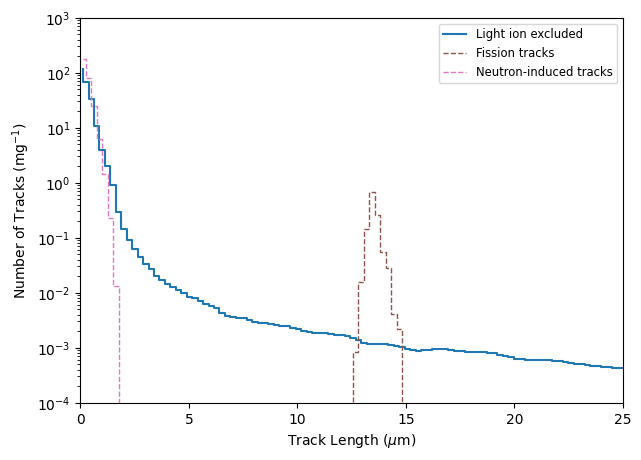

In [11]:
x_mids = x_bins[:-1] + np.diff(x_bins) / 2

fig, ax = plt.subplots(figsize=[7, 5])

spec = 'total'

#ax.fill_between(x_mids/1000, tracks_simple_slow[spec], tracks_simple_fast[spec], alpha=0.7, label=f'Simple Scenario Range')
#ax.fill_between(x_mids/1000, tracks_SN20_slow[spec], tracks_SN20_fast[spec], color='C1', alpha=0.4, label='SN20 Scenario Range')
#ax.fill_between(x_mids/1000, tracks_SN100_slow[spec], tracks_SN100_fast[spec], color='C2', alpha=0.4, label='SN100 Scenario Range')

#ax.fill_between(x_mids/1000, tracks_post_slow[spec], tracks_post_fast[spec], color='C3', alpha=0.4, label='Post-Event Scenario Range')

ax.step(x_mids/1000, tracks_simple_fast[spec], label="Light ion excluded")
   
ax.step(x_mids/1000, total_fission_tracks, color='C5', linestyle='dashed', linewidth=1., label="Fission tracks", where='mid')
ax.step(x_mids/1000, total_neutron_tracks, color='C6', linestyle='dashed', linewidth=1., label="Neutron-induced tracks", where='mid')

ax.set_xlabel(r"Track Length ($\mu$m)")
ax.set_ylabel(r"Number of Tracks (mg$^{-1}$)")
ax.set_yscale("log")
ax.set_ylim(1e-4, 1e3)
ax.set_xlim(0, 25)
ax.legend(fontsize='small')
plt.show()

In [12]:
sliced_bkg = slice_spectrum_etch(total_neutron_tracks + total_fission_tracks, sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral_config["density_g_cm3"], etch_type='HF')

sliced_simple_fast = slice_spectrum_etch(tracks_simple_fast[spec], sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral_config["density_g_cm3"], etch_type='HF')


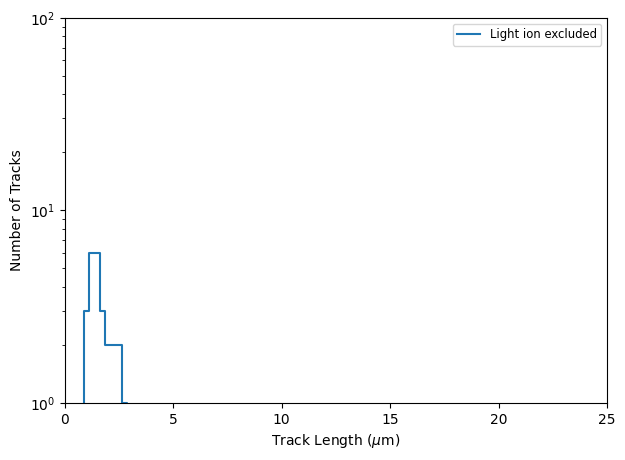

In [13]:
x_mids = x_bins[:-1] + np.diff(x_bins) / 2

fig, ax = plt.subplots(figsize=[7, 5])

ax.step(x_mids/1000, sliced_simple_fast + sliced_bkg, label="Light ion excluded")
   
ax.set_xlabel(r"Track Length ($\mu$m)")
ax.set_ylabel(r"Number of Tracks")
ax.set_yscale("log")
ax.set_ylim(1e0, 1e2)
ax.set_xlim(0, 25)
ax.legend(fontsize='small')
plt.show()